# Notebook 01: Pipeline Validation — Recovering a Known Planet

**Purpose:** Demonstrate that the `tesshunter` pipeline can recover a known confirmed exoplanet signal from TESS data before attempting any unknown candidate search.

**Target:** WASP-126 b (TIC 25155310) — a hot Jupiter with a well-characterised, deep (~2.5 ppt) transit at a period of ~3.29 days. Selected because it is bright, clean, and unambiguous.

**Pass criterion:** BLS must recover a period within 2% of the published value (3.2883 days).

> Scientific note: this notebook does not 'discover' anything. It verifies the pipeline works correctly on a known signal.

In [1]:
import sys
import logging
sys.path.insert(0, '../src')

logging.basicConfig(level=logging.INFO, format='%(levelname)s %(name)s: %(message)s')

import matplotlib
matplotlib.use('inline')
import matplotlib.pyplot as plt
%matplotlib inline

from tesshunter import download, preprocessing, bls_search, plotting, catalog_crossmatch
from tesshunter.config import PLOTS_DIR

C:\Users\samzu\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## 1. Target Definition

In [2]:
TIC_ID = 25155310            # WASP-126
KNOWN_PERIOD = 3.2883        # days (published value)
KNOWN_DEPTH_PPT = 2.5        # ppt
TARGET_LABEL = f"TIC {TIC_ID}"

print(f"Target: WASP-126 b (TIC {TIC_ID})")
print(f"Expected period: {KNOWN_PERIOD:.4f} d")
print(f"Expected depth:  {KNOWN_DEPTH_PPT:.1f} ppt")

Target: WASP-126 b (TIC 25155310)
Expected period: 3.2883 d
Expected depth:  2.5 ppt


## 2. Download Light Curve

In [3]:
lcc = download.search_and_download(TIC_ID, flux_type='PDCSAP_FLUX')

if lcc is None:
    raise RuntimeError(f"No data found for TIC {TIC_ID}.")

# ── Limit to 2 sectors for validation ──────────────────────────────────────
lcc = lcc[:2]
# ────────────────────────────────────────────────────────────────────────────

sectors = download.sectors_available(lcc)
print(f"Using {len(lcc)} sector(s): {sectors}")

INFO tesshunter.download: Searching MAST for TIC 25155310 (exptime=120, sector=None)
INFO tesshunter.download: Attempting to download 48 product(s)...
5% (983/19261) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
INFO lightkurve.utils: 5% (983/19261) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2% (399/18699) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
INFO lightkurve.utils: 2% (399/18699) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
WARNING lightkurve.utils: Warning: 30% (5871/19412) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2% (281/15973) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
INFO lightkurve.utils: 2% (281/15973) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2% (297/17971) of the cadences will be ignored due to the quality mask 

Using 2 sector(s): [1, 2]


In [4]:
import warnings
warnings.filterwarnings('ignore', message='.*zero-centered.*')

# Normalize each sector to median=1 BEFORE stitching
lcc_normed = [lc.normalize() for lc in lcc]
lc_raw = download.stitch_collection(lcc_normed)

print(f"Cadences: {len(lc_raw)}  |  "
      f"Flux median: {lc_raw.flux.value.__array__().mean():.4f}  "
      f"std: {lc_raw.flux.value.__array__().std():.6f}")
print(f"Stitched: {len(lc_raw)} cadences, spanning "
      f"{lc_raw.time.max().value - lc_raw.time.min().value:.1f} days")

INFO tesshunter.download: Stitched 2 sectors → 36578 cadences spanning 56.2 days (median flux ~1.0)


Cadences: 36578  |  Flux median: 0.9998  std: 0.001847
Stitched: 36578 cadences, spanning 56.2 days


## 3. Preprocessing

In [5]:
lc_clean, prep_record = preprocessing.preprocess(
    lc_raw,
    sigma=4.0,
    do_flatten=True,
    flatten_window=0.5,
)

print(f"Preprocessing complete.")
for note in prep_record.notes:
    print(f"  {note}")

INFO tesshunter.preprocessing: Preprocessing complete: 36578 → 36577 cadences


Preprocessing complete.
  Removed 1 cadences (0.0%)


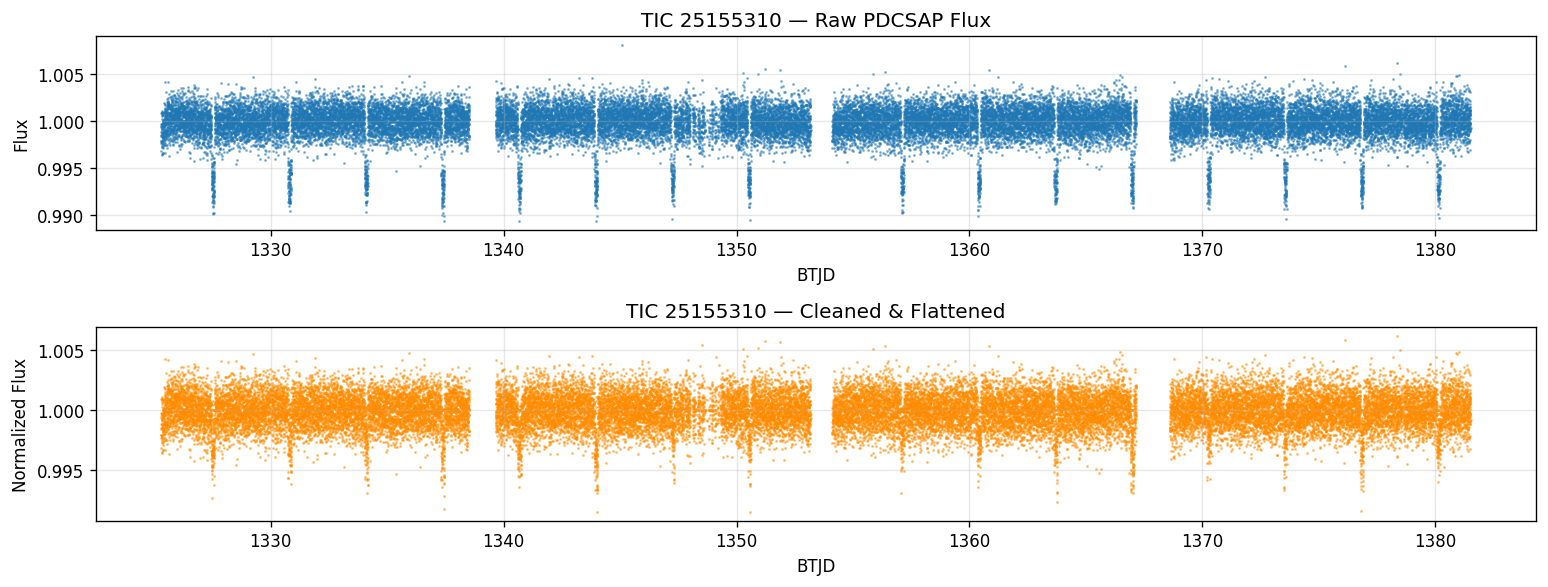

INFO tesshunter.preprocessing: Binned 36577 → 7480 cadences (10-min bins)


Binned: 36577 → 7480 cadences


In [6]:
# Quick inline plots
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=False)
axes[0].scatter(lc_raw.time.value, lc_raw.flux.value, s=0.5, alpha=0.5)
axes[0].set_title(f"{TARGET_LABEL} — Raw PDCSAP Flux")
axes[0].set_xlabel("BTJD")
axes[0].set_ylabel("Flux")

axes[1].scatter(lc_clean.time.value, lc_clean.flux.value, s=0.5, alpha=0.5, color='darkorange')
axes[1].set_title(f"{TARGET_LABEL} — Cleaned & Flattened")
axes[1].set_xlabel("BTJD")
axes[1].set_ylabel("Normalized Flux")
plt.tight_layout()
plt.show()
# Bin to 10-minute cadence — reduces ~18,000 points to ~3,600
lc_binned = preprocessing.bin_lightcurve(lc_clean, bin_minutes=10.0)
print(f"Binned: {len(lc_clean)} → {len(lc_binned)} cadences")

## 4. BLS Transit Search

In [7]:
bls_model, bls_result, candidates = bls_search.run_bls(
    lc_binned,          # ← was lc_clean
    period_min=0.5,
    period_max=15.0,
    duration_min=0.05,
    duration_max=0.4,
    top_n=5,
)
print(candidates[['peak_rank','period_days','depth_ppt','duration_days','power','snr']].to_string(index=False))

INFO tesshunter.bls_search: BLS search: periods 0.50–15.00 d, 1086 freq points, 12 durations
INFO tesshunter.bls_search: Dropped 1 ghost candidate(s) with depth≤0 or SNR≤0
INFO tesshunter.bls_search: BLS complete. Top candidate period: 3.2890 d


 peak_rank  period_days  depth_ppt  duration_days       power       snr
         1     3.289039   2.622662           0.13 2669.762585 71.602139
         2     1.095256   0.759795           0.13  684.624726 34.645021
         3     0.822248   0.581962           0.05  648.950280 19.522170
         4     0.657706   0.169844           0.40  481.528450 11.553628


## 5. Validation Check

In [8]:
best = candidates.iloc[0]
recovered_period = best['period_days']
tolerance = 0.02  # 2%

# Allow harmonic aliases
aliases = [KNOWN_PERIOD, KNOWN_PERIOD/2, KNOWN_PERIOD*2]
match = min(abs(recovered_period - a) / a for a in aliases)
PASS = match < tolerance

print(f"Known period:     {KNOWN_PERIOD:.4f} d")
print(f"Recovered period: {recovered_period:.4f} d")
print(f"Fractional error: {match*100:.2f}%")
print()
print(f"VALIDATION: {'✓ PASS' if PASS else '✗ FAIL'}")
if not PASS:
    print("WARNING: Period not recovered within 2% tolerance.")
    print("Check data quality, sector coverage, and BLS parameter range.")

Known period:     3.2883 d
Recovered period: 3.2890 d
Fractional error: 0.02%

VALIDATION: ✓ PASS


## 6. BLS Periodogram

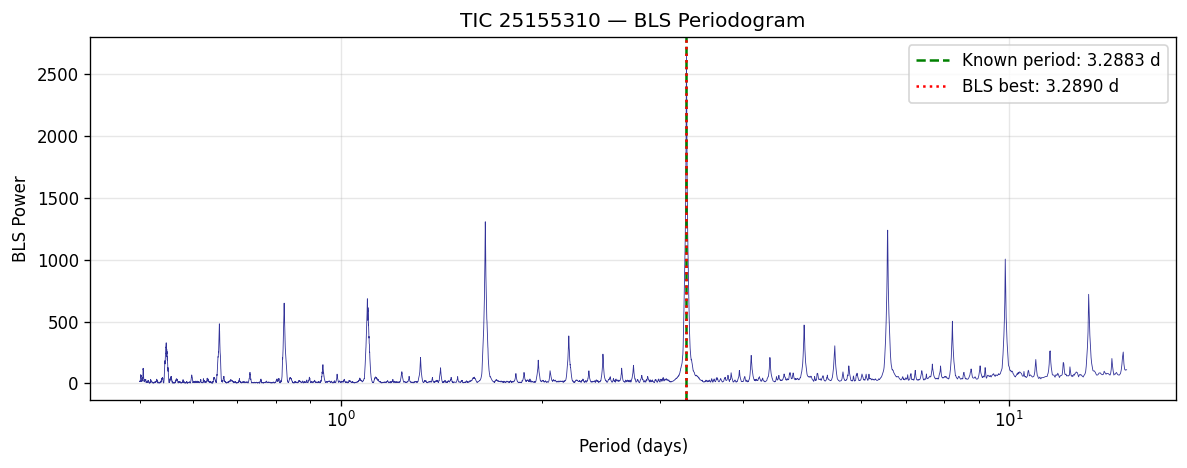

In [9]:
import numpy as np

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(bls_result.period.value, bls_result.power, lw=0.5, color='navy', alpha=0.8)
ax.axvline(KNOWN_PERIOD, color='green', ls='--', lw=1.5, label=f'Known period: {KNOWN_PERIOD:.4f} d')
ax.axvline(recovered_period, color='red', ls=':', lw=1.5, label=f'BLS best: {recovered_period:.4f} d')
ax.set_xscale('log')
ax.set_xlabel('Period (days)')
ax.set_ylabel('BLS Power')
ax.set_title(f'{TARGET_LABEL} — BLS Periodogram')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Phase-Folded Light Curve

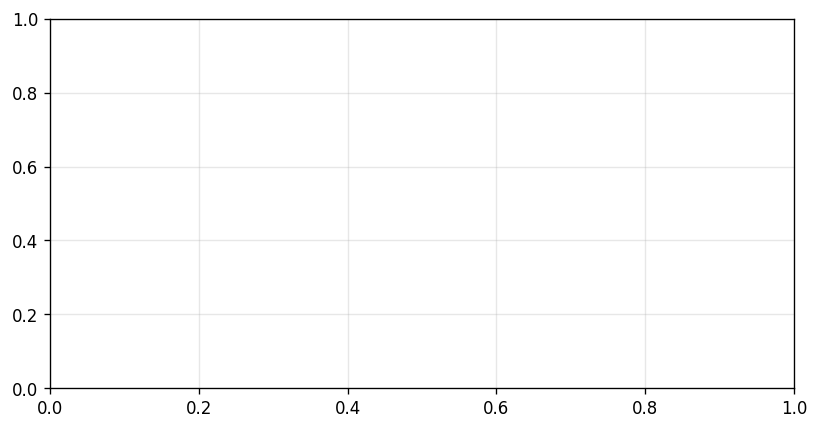

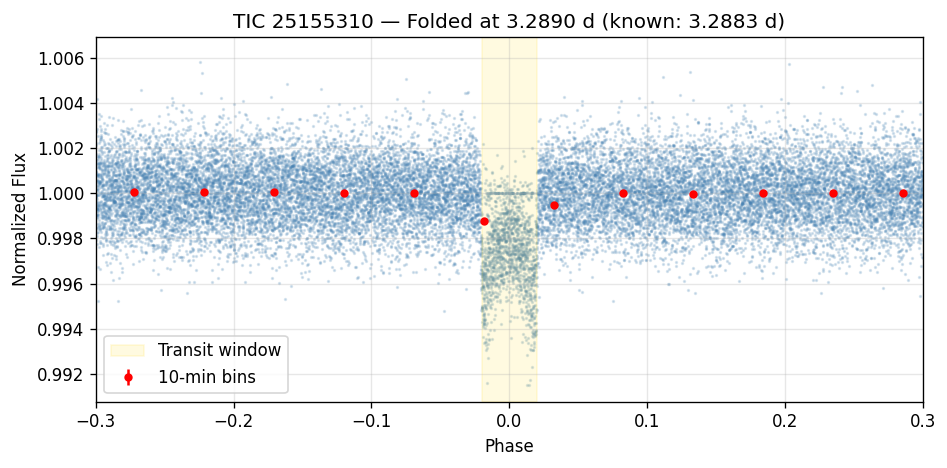

In [10]:
from tesshunter.utils import phase_fold

period = best['period_days']
epoch  = best['epoch_btjd']
duration = best['duration_days']

time  = lc_clean.time.value
flux  = lc_clean.flux.value
phase = phase_fold(time, period, epoch)
sort  = np.argsort(phase)

# Bin
bin_width = (10/60) / period  # 10-minute bins in phase units
bins = np.arange(-0.5, 0.5, bin_width)
bc, bf, be = [], [], []
for b in bins:
    m = (phase[sort] >= b) & (phase[sort] < b + bin_width)
    if m.sum() > 2:
        bc.append(b + bin_width/2)
        bf.append(np.nanmedian(flux[sort][m]))
        be.append(np.nanstd(flux[sort][m]) / np.sqrt(m.sum()))

# Force plain float arrays — strips any astropy masked-array metadata
bc = np.array(bc, dtype=float)
bf = np.array(bf, dtype=float)
be = np.array(be, dtype=float)

fig, ax = plt.subplots(figsize=(8, 4))
...

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(phase[sort], flux[sort], s=1, alpha=0.2, c='steelblue')
ax.errorbar(bc, bf, yerr=be, fmt='o', color='red', ms=4, lw=1.5, zorder=5, label='10-min bins')
ax.axvspan(-duration/period/2, duration/period/2, alpha=0.12, color='gold', label='Transit window')
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel('Phase')
ax.set_ylabel('Normalized Flux')
ax.set_title(f'{TARGET_LABEL} — Folded at {period:.4f} d (known: {KNOWN_PERIOD:.4f} d)')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Summary

If the validation check above shows **PASS**, the pipeline is correctly recovering known transit signals and is ready for use on unknown targets.

If it shows **FAIL**:
- Inspect the periodogram — the known period should still show a visible peak
- Check that sufficient sectors were downloaded (ideally ≥2)
- Try disabling flattening and re-running BLS
- The known period may appear as a harmonic alias (0.5× or 2×)